# Neural network: final model

Run the cells from top to bottom. This notebook is self-contained: it trains
the NN from scratch and evaluates it using the shared data and installed
NumPy, PyTorch, scikit-learn and Matplotlib libraries. It does not load any
project scripts, saved models or tuning results.

Run it from `24_10_2026_TianFeng`, using a Python notebook kernel with
those libraries installed. `../` means the parent folder, where the shared
dataset and `Minh` folder are already stored.

The shared dataset folder has no `Train/X_train.txt`. Training features are
read from the existing `Minh/hapt_train.csv`, which contains the same
7,767 rows and 561 feature values in the same order. The CSV is only read;
its three metadata columns are excluded from the NN inputs.

The hyperparameters and **34 training epochs** are already selected. There
is no tuning or cross-validation loop here. The flow is:

**Load training data → balance classes → scale and PCA → train the MLP
→ predict test windows → apply posture memory → print metrics and plot the matrix.**


## 1. Imports

NumPy handles the data; scikit-learn supplies scaling, PCA and metrics;
PyTorch trains the network; Matplotlib displays the plots. The thread and
seed settings help reproduce the existing training run on this environment.


In [1]:
import os
from pathlib import Path

for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ.setdefault(name, '2')

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_fscore_support
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.set_num_threads(2)
np.set_printoptions(precision=4, suppress=True)


## 2. Fixed settings

These are the selected settings: Adam learning rate 0.001, weight decay
0.0001, 200 PCA components, at most 300 training examples per common class,
and batches of 128. We train for 34 epochs, the duration selected in the
earlier participant-validation study, so this final fit needs no patience
counter. The network architecture is defined in step 6.

The dataset already exists in the parent folder. The direct `../` path below
reads it from this notebook folder; no folder search is needed.


In [2]:
data = Path('../smartphone+based+recognition+of+human+activities+and+postural+transitions')

SEED = 42
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
PCA_COMPONENTS = 200
CLASS_LIMIT = 300
BATCH_SIZE = 128
EPOCHS = 34
memory = {'steps': 8, 'alpha': 1.0, 'minimum_static_mass': 0.75}


## 3. Read the training data

The shared training CSV starts with `subject_id`, `activity_id` and
`activity_label`. Skip its header and select columns 3–563 (zero-based) to
read only the 561 sensor features. Excluding the metadata prevents activity
labels and participant IDs from entering the NN inputs.

The activity and participant text files in the shared dataset use the same
row order. Subtracting 1 changes activity labels 1–12 into output indices 0–11.


In [3]:
X = np.loadtxt('../Minh/hapt_train.csv', delimiter=',',
               skiprows=1, usecols=range(3, 564), dtype=np.float32)
y = np.loadtxt(data / 'Train/y_train.txt', dtype=int) - 1
subject = np.loadtxt(data / 'Train/subject_id_train.txt', dtype=int)
names = np.loadtxt(data / 'activity_labels.txt', dtype=str)[:, 1].tolist()


print(f'Training data: {len(X)} windows, {X.shape[1]} features, {len(np.unique(subject))} participants')


Training data: 7767 windows, 561 features, 21 participants


## 4. Check and reduce class imbalance

The first six common activities have many more windows than the six
transitions. We randomly retain at most 300 rows from each common class and
keep every transition. `sampled` contains the selected row indices. The table
shows the class counts before and after sampling. Test rows are not sampled.

This reduces dominance by common activities, at the cost of discarding some
of their training examples. Weighted loss in step 6 also gives more weight
to classes that remain rare.


In [4]:
rng = np.random.default_rng(SEED)
selected = []
for activity in range(12):
    rows = np.flatnonzero(y == activity)
    if activity < 6 and len(rows) > CLASS_LIMIT:
        rows = rng.choice(rows, CLASS_LIMIT, replace=False)
    selected.extend(rows)
sampled = np.sort(selected)


train_y = y[sampled]
original_counts = np.bincount(y, minlength=12)
sampled_counts = np.bincount(train_y, minlength=12)
print(f'{"Activity":22} {"Original":>9} {"Used":>9}')
for activity, name in enumerate(names):
    print(f'{name:22} {original_counts[activity]:9d} {sampled_counts[activity]:9d}')
print(f'Total training rows: {len(y)} -> {len(train_y)}')


Activity                Original      Used
WALKING                     1226       300
WALKING_UPSTAIRS            1073       300
WALKING_DOWNSTAIRS           987       300
SITTING                     1293       300
STANDING                    1423       300
LAYING                      1413       300
STAND_TO_SIT                  47        47
SIT_TO_STAND                  23        23
SIT_TO_LIE                    75        75
LIE_TO_SIT                    60        60
STAND_TO_LIE                  90        90
LIE_TO_STAND                  57        57
Total training rows: 7767 -> 2152


## 5. Scale the features and apply PCA

The scaler learns the mean and scale of each feature from the sampled
training rows. PCA then learns 200 directions from those scaled rows.
`fit_transform` both learns the transformation and applies it. Keep `scaler`
and `pca`: test data must use their training values, without fitting again.


In [5]:
scaler = StandardScaler()
train_x = scaler.fit_transform(X[sampled]).astype(np.float32)
pca = PCA(n_components=PCA_COMPONENTS, svd_solver='randomized', random_state=SEED)
train_x = pca.fit_transform(train_x).astype(np.float32)

print('Training input after PCA:', train_x.shape)


Training input after PCA: (2152, 200)


## 6. Build the NN, loss weights and optimiser

The MLP is **200 → 256 → 128 → 64 → 12**, with ReLU hidden activations.
Batch normalisation follows the first two hidden linear layers; dropout
rates are 0.3, 0.3 and 0.2. The final layer returns logits for cross-entropy.
Kaiming initialisation is used before ReLU and Xavier for the output layer.

The class weight is `training rows / (12 × class count)`, calculated after
sampling. Adam updates the network weights. `DataLoader` shuffles training
rows and divides them into batches; it does not shuffle the test sequence.


In [6]:
torch.manual_seed(SEED)
model = nn.Sequential(
    nn.Linear(PCA_COMPONENTS, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(64, 12),
)
for layer in model:
    if isinstance(layer, nn.Linear):
        if layer.out_features == 12:
            nn.init.xavier_uniform_(layer.weight)
        else:
            nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
        nn.init.zeros_(layer.bias)

counts = np.bincount(train_y, minlength=12)
weights = torch.tensor(len(train_y) / (12 * counts), dtype=torch.float32)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
loader = DataLoader(TensorDataset(torch.from_numpy(train_x), torch.from_numpy(train_y)),
                    batch_size=BATCH_SIZE, shuffle=True,
                    generator=torch.Generator().manual_seed(SEED))


## 7. Train for 34 epochs

The outer loop runs over epochs; the inner loop visits all training batches.
For each batch: clear old gradients, predict logits, calculate weighted
cross-entropy, backpropagate, then update weights. Dividing by the sum of
class weights gives the weighted mean loss used by the current model.

After each epoch, `eval()` switches off dropout and uses stored batch-normalisation
statistics. `no_grad()` measures whole-training-set loss without tracking gradients.
We print progress at the first epoch, every fifth epoch and the final epoch.


In [7]:
train_losses = []
batch_losses = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    for batch_x, batch_y in loader:
        optimizer.zero_grad()
        logits = model(batch_x)
        losses = F.cross_entropy(logits, batch_y, reduction='none')
        loss = (losses * weights[batch_y]).sum() / weights[batch_y].sum()
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        target = torch.from_numpy(train_y)
        logits = model(torch.from_numpy(train_x))
        losses = F.cross_entropy(logits, target, reduction='none')
        train_loss = (losses * weights[target]).sum() / weights[target].sum()
    train_losses.append(train_loss.item())
    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        print(f'Epoch {epoch:2d}/{EPOCHS}: training loss {train_loss.item():.4f}')


Epoch  1/34: training loss 1.6042
Epoch  5/34: training loss 0.4936
Epoch 10/34: training loss 0.2080
Epoch 15/34: training loss 0.0899
Epoch 20/34: training loss 0.0435
Epoch 25/34: training loss 0.0219
Epoch 30/34: training loss 0.0115
Epoch 34/34: training loss 0.0082


## 8. Plot training loss

The left plot measures the whole training set after each epoch, with dropout
off. The right plot shows individual batch losses during training: changing
batch contents and dropout create the zigzag pattern.

These are training curves, so they show optimisation behaviour. They cannot
establish whether this final fit overfits; that requires held-out validation.
This notebook uses the previously selected duration rather than rerunning
that validation study.


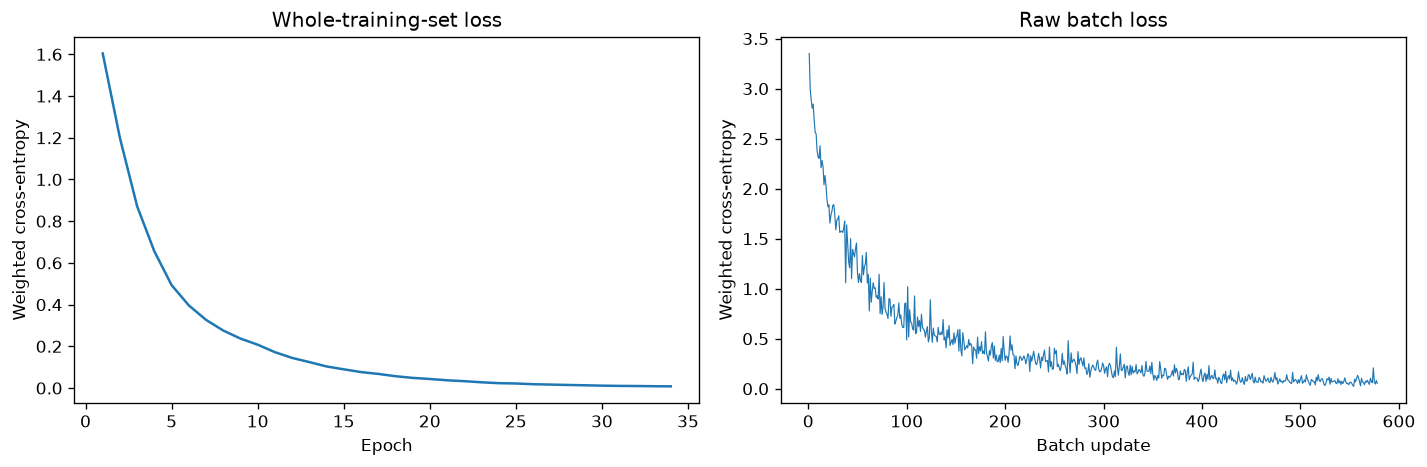

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, EPOCHS + 1), train_losses)
axes[0].set(title='Whole-training-set loss', xlabel='Epoch', ylabel='Weighted cross-entropy')
axes[1].plot(range(1, len(batch_losses) + 1), batch_losses, linewidth=0.7)
axes[1].set(title='Raw batch loss', xlabel='Batch update', ylabel='Weighted cross-entropy')
fig.tight_layout()
plt.show()


## 9. Predict the test windows

Read test features and participant IDs in their original order. Use the
training scaler and PCA values; the explicit float32 calculation matches
the existing model's inference. Each window becomes 200 inputs.

The trained network returns 12 logits. Softmax turns them into scores
summing to one, and `argmax` selects the largest. `baseline` holds these
plain NN predictions. The test activity labels have not been loaded yet.


In [9]:
X_test = np.loadtxt(data / 'Test/X_test.txt', dtype=np.float32)
test_subject = np.loadtxt(data / 'Test/subject_id_test.txt', dtype=int)

scaled_test = (X_test - scaler.mean_.astype(np.float32)) / scaler.scale_.astype(np.float32)
test_x = ((scaled_test - pca.mean_.astype(np.float32))
          @ pca.components_.astype(np.float32).T).astype(np.float32)

model.eval()
with torch.no_grad():
    probabilities = model(torch.from_numpy(test_x)).softmax(dim=1).numpy()
baseline = probabilities.argmax(axis=1)


## 10. Apply the selected posture-memory rule

When the NN predicts sit-to-lie (index 8) or stand-to-lie (index 10), look
at up to eight **earlier** windows from that participant. Sum their sitting
and standing scores (indices 3 and 4). With combined score mass at least
0.75, the fraction coming from standing determines the starting posture:
above 0.5 chooses stand-to-lie; otherwise sit-to-lie. Insufficient evidence
keeps the original conditional score. Alpha 1 gives the past score full weight.

Only those two output labels can change. This is postprocessing, not a
new NN input or trainable layer. It uses earlier NN scores, never true labels,
and history resets at a participant boundary. The scores are uncalibrated;
0.75 is a sum across history, not a 75% confidence guarantee.

The method assumes contiguous, chronological rows. A separate recording
from the same person needs a separate sequence ID to reset the history.


In [10]:
predictions = baseline.copy()
gate = np.isin(baseline, [8, 10])
pair_mass = probabilities[:, [8, 10]].sum(axis=1)
current_score = np.divide(probabilities[:, 10], pair_mass,
                          out=np.full(len(X_test), 0.5), where=pair_mass > 0)
past_score = current_score.copy()
evidence = np.zeros(len(X_test))
start = 0

for row in range(len(X_test)):
    if row == 0 or test_subject[row] != test_subject[row - 1]:
        start = row
    first = max(start, row - memory['steps'])
    previous = probabilities[first:row, [3, 4]].sum(axis=0)
    evidence[row] = previous.sum()
    if evidence[row] >= memory['minimum_static_mass']:
        past_score[row] = previous[1] / evidence[row]

score = (1 - memory['alpha']) * current_score + memory['alpha'] * past_score
predictions[gate] = np.where(score[gate] > 0.5, 10, 8)
changed = np.flatnonzero(predictions != baseline)

print(f'Posture memory changed {len(changed)} predictions.')


Posture memory changed 20 predictions.


## 11. Evaluate the predictions

Now load test labels to compare the plain NN with NN + memory. Accuracy
counts all correct windows; macro-F1 gives each of the 12 classes equal
weight. Transition F1 averages only the last six classes.

The class table gives precision, recall, F1 and correct/support. **Class
accuracy means recall**, shown as a percentage; it is not a separate metric.
Small class supports mean a few windows can substantially change the scores.


In [11]:
y_test = np.loadtxt(data / 'Test/y_test.txt', dtype=int) - 1

print(f'{"Method":23} {"Accuracy":>10} {"Macro-F1":>10} {"Transition F1":>15}')
for title, labels in [('MLP', baseline), ('MLP + posture memory', predictions)]:
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, labels, labels=range(12), zero_division=0)
    print(f'{title:23} {100 * np.mean(y_test == labels):9.4f}%'
          f' {f1.mean():10.6f} {f1[6:].mean():15.6f}')

print('\nMLP + posture memory: all 12 classes')
print(f'{"Activity":22} {"Precision":>9} {"Recall":>9} {"F1":>9}'
      f' {"Class acc %":>12} {"Correct/N":>11}')
for activity, name in enumerate(names):
    correct = np.sum((y_test == activity) & (predictions == activity))
    recognized = f'{correct}/{support[activity]}'
    print(f'{name:22} {precision[activity]:9.4f} {recall[activity]:9.4f}'
          f' {f1[activity]:9.4f} {100 * recall[activity]:12.2f} {recognized:>11}')


Method                    Accuracy   Macro-F1   Transition F1
MLP                       93.4535%   0.844794        0.741949
MLP + posture memory      94.0860%   0.886602        0.825564

MLP + posture memory: all 12 classes
Activity               Precision    Recall        F1  Class acc %   Correct/N
WALKING                   0.9494    0.9839    0.9663        98.39     488/496
WALKING_UPSTAIRS          0.9653    0.9448    0.9549        94.48     445/471
WALKING_DOWNSTAIRS        0.9852    0.9500    0.9673        95.00     399/420
SITTING                   0.9308    0.8740    0.9015        87.40     444/508
STANDING                  0.8792    0.9424    0.9097        94.24     524/556
LAYING                    1.0000    0.9725    0.9860        97.25     530/545
STAND_TO_SIT              0.7037    0.8261    0.7600        82.61       19/23
SIT_TO_STAND              0.7143    1.0000    0.8333       100.00       10/10
SIT_TO_LIE                1.0000    0.9688    0.9841        96.88       31

## 12. Display the confusion matrix

Rows are actual activities and columns are predictions. The diagonal counts
correct predictions; off-diagonal counts show the remaining confusions.
Overall accuracy and macro-F1 appear in the title.

Posture memory only swaps sit-to-lie and stand-to-lie. It cannot recover
either class if the original NN predicted outside that pair, and it leaves
the other ten classes' metrics unchanged, including lie-to-sit.


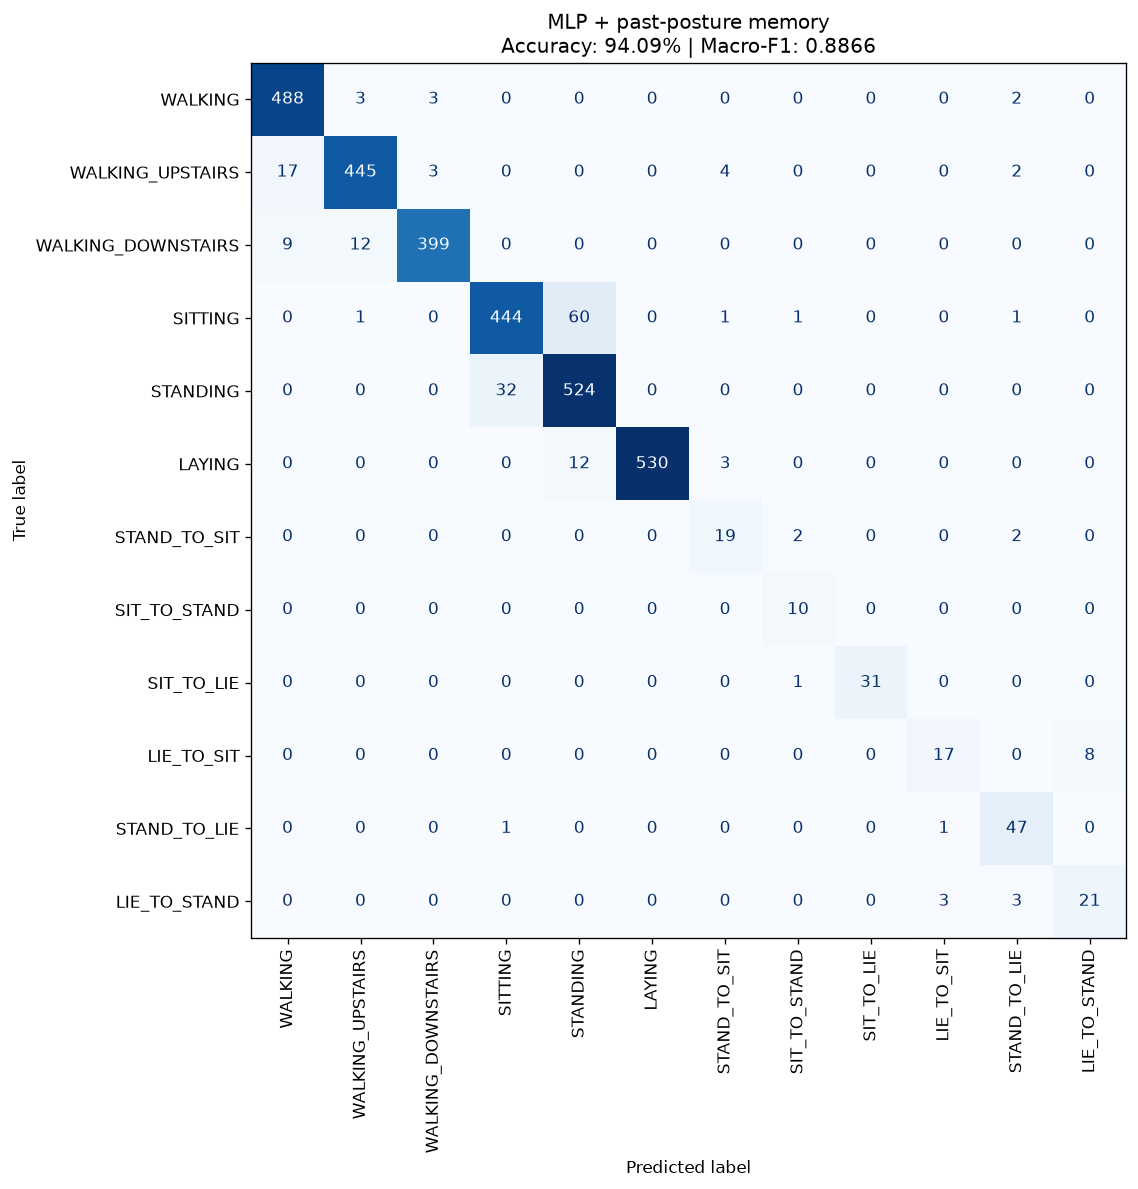

In [12]:
matrix = confusion_matrix(y_test, predictions, labels=range(12))
accuracy = np.mean(y_test == predictions)
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(matrix, display_labels=names).plot(
    ax=ax, cmap='Blues', values_format='d', xticks_rotation=90, colorbar=False)
ax.set_title(f'MLP + past-posture memory\nAccuracy: {100 * accuracy:.2f}% | Macro-F1: {f1.mean():.4f}')
fig.tight_layout()
plt.show()


The trained model, scaler and PCA remain in memory; no files are written.
It needs only the shared data files and installed libraries; other model
code and saved checkpoints are not needed.

These reproduce developmental test results: the supplied test set was
inspected earlier in the project, and the memory rule assumes row chronology.
